In [10]:
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="Set2")

# Configuración de gráficos
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [6]:
# Carga del dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
# Comprobamos la carga
print("Dataset cargado correctamente")

Dataset cargado correctamente


In [7]:
# Primeras cinco filas
display(df.head())

# Últimas cinco filas
display(df.tail())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [ ]:
print(f"Número de registros: {df.shape[0]}")
print(f"Número de columnas: {df.shape[1]}")
print(f"Dimensiones: {df.shape}")

Número de registros: 7043
Número de columnas: 21
Dimensiones: (7043, 21)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
display(
    pd.DataFrame({
        "Variable": df.columns,
        "Tipo de dato": df.dtypes.values,
        "Valores únicos": df.nunique().values
    })
)

,Variable,Tipo de dato,Valores únicos
0,customerID,object,7043
1,gender,object,2
2,SeniorCitizen,int64,2
3,Partner,object,2
4,Dependents,object,2
5,tenure,int64,73
6,PhoneService,object,2
7,MultipleLines,object,3
8,InternetService,object,3
9,OnlineSecurity,object,3


In [ ]:
# Valores nulos por columna
missing = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje": (df.isnull().sum() / len(df)) * 100
})

display(missing.sort_values("Nulos", ascending=False))

,Nulos,Porcentaje
customerID,0,0.00
gender,0,0.00
SeniorCitizen,0,0.00
Partner,0,0.00
Dependents,0,0.00
tenure,0,0.00
PhoneService,0,0.00
MultipleLines,0,0.00
InternetService,0,0.00
OnlineSecurity,0,0.00


In [ ]:
# Detectar cadenas vacías o con espacios
blank_values = (
    df.select_dtypes(include="object")
      .apply(lambda col: col.str.strip().eq("").sum())
)

display(blank_values[blank_values > 0])

,0
TotalCharges,11


In [ ]:
# Duplicados completos
print("Registros duplicados:", df.duplicated().sum())

# Identificadores duplicados
print("CustomerID duplicados:", df["customerID"].duplicated().sum())

Registros duplicados: 0
CustomerID duplicados: 0


In [ ]:
# Variables numéricas
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,"7,043.00","7,043.00","7,043.00"
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [ ]:
display(df.describe(include="object"))

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [ ]:
# Frecuencias absolutas
print(df["Churn"].value_counts())

# Frecuencias relativas
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No    73.46
Yes   26.54
Name: proportion, dtype: float64


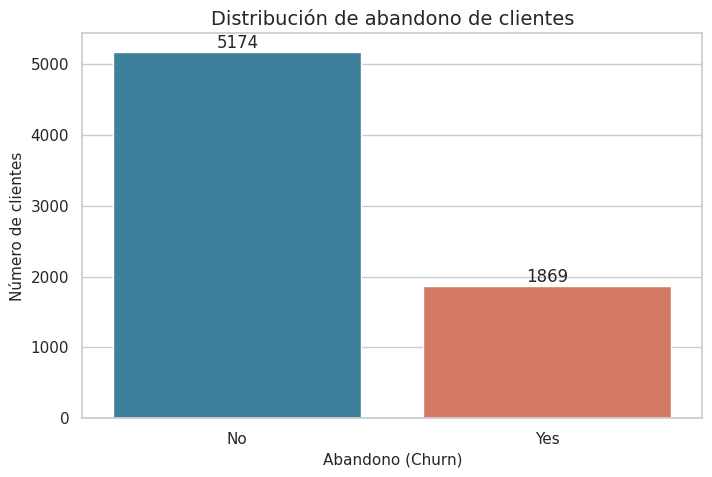

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette={"No": "#2E86AB", "Yes": "#E76F51"},
    legend=False
)

plt.title("Distribución de abandono de clientes")
plt.xlabel("Abandono (Churn)")
plt.ylabel("Número de clientes")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.show()

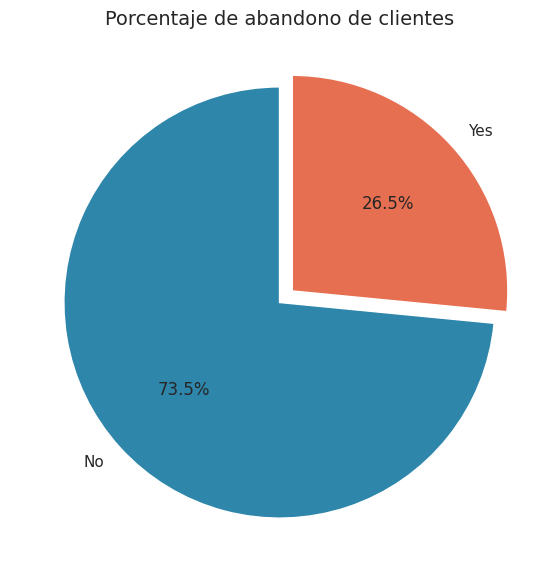

In [ ]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))

plt.pie(
    churn_percentage,
    labels=churn_percentage.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2E86AB", "#E76F51"],
    explode=(0, 0.08)
)

plt.title("Porcentaje de abandono de clientes")
plt.show()

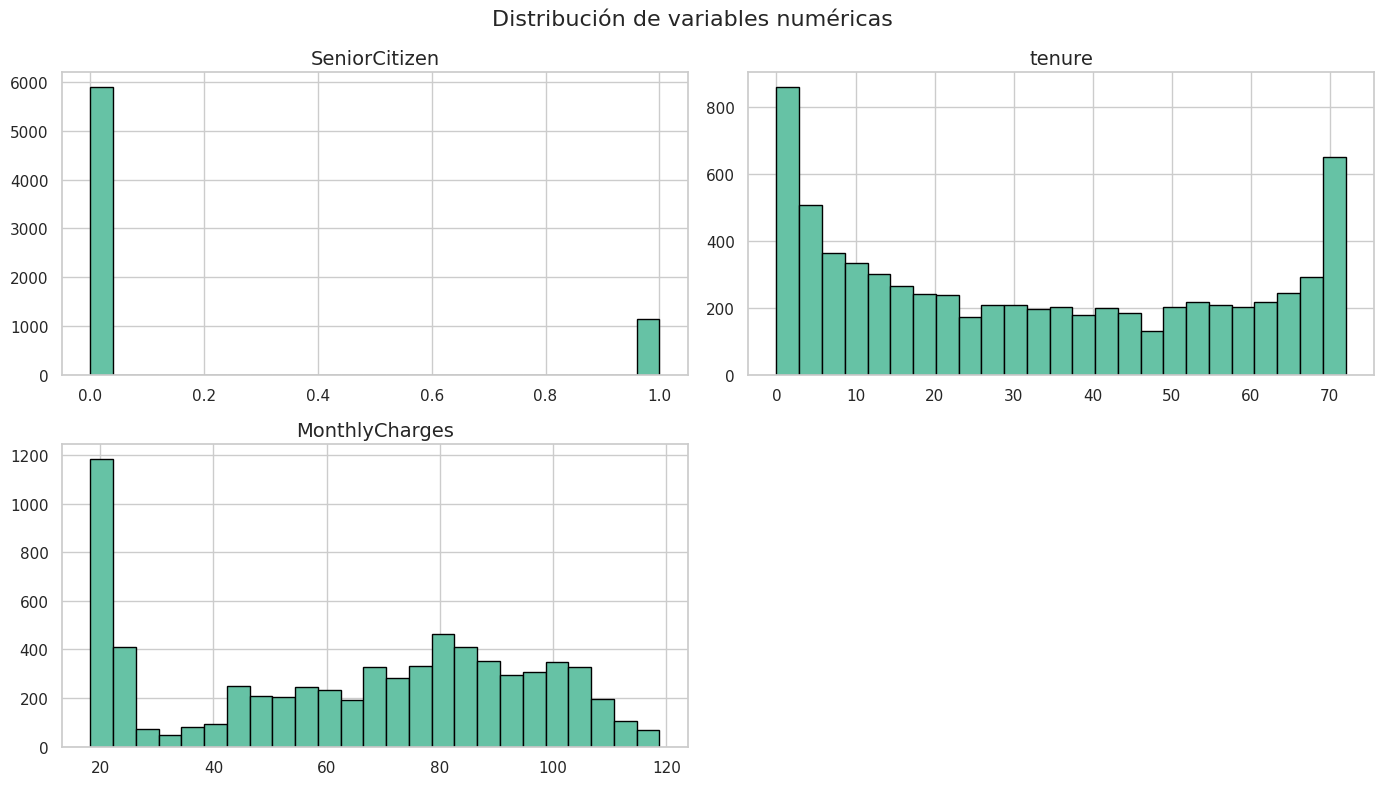

In [ ]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

df[numeric_columns].hist(
    bins=25,
    figsize=(14, 8),
    edgecolor="black"
)

plt.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

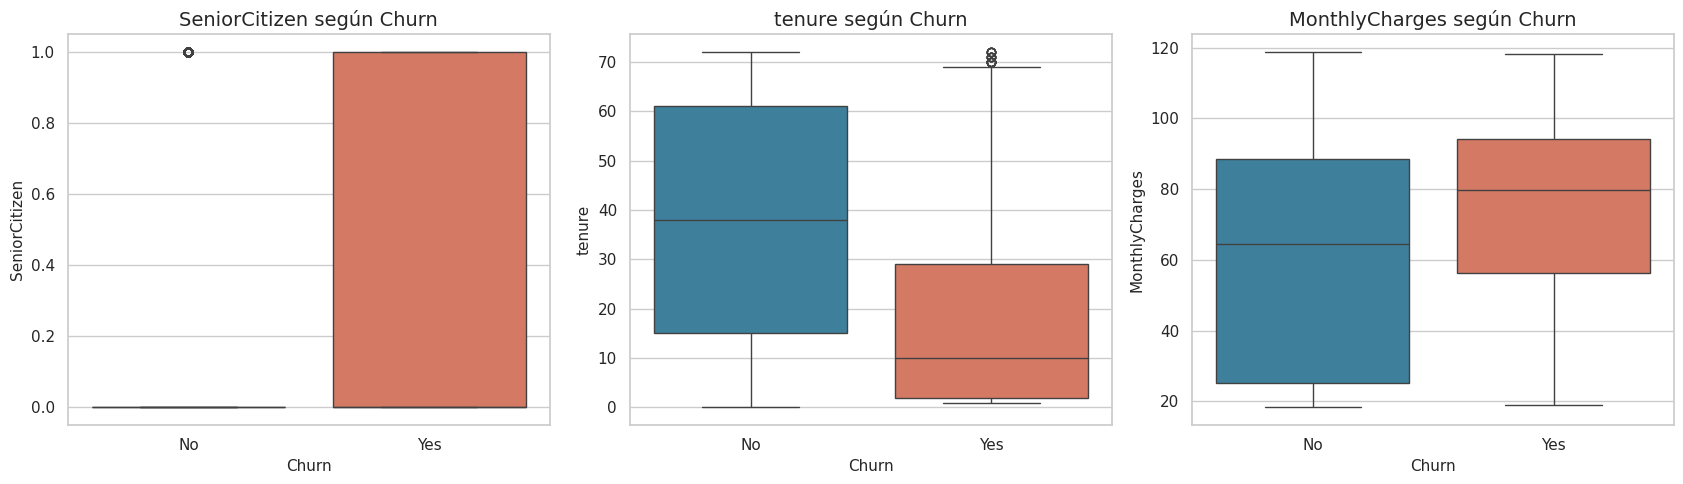

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i, column in enumerate(numeric_columns):

    sns.boxplot(
        data=df,
        x="Churn",
        y=column,
        hue="Churn",
        ax=axes[i],
        palette={"No": "#2E86AB", "Yes": "#E76F51"},
        legend=False
    )

    axes[i].set_title(f"{column} según Churn")

plt.tight_layout()
plt.show()

In [ ]:
df_eda = df.copy()

df_eda["TotalCharges"] = pd.to_numeric(
    df_eda["TotalCharges"].str.strip(),
    errors="coerce"
)

# Comprobamos el resultado
print(df_eda["TotalCharges"].dtype)
print("Valores nulos en TotalCharges:", df_eda["TotalCharges"].isnull().sum())

float64
Valores nulos en TotalCharges: 11


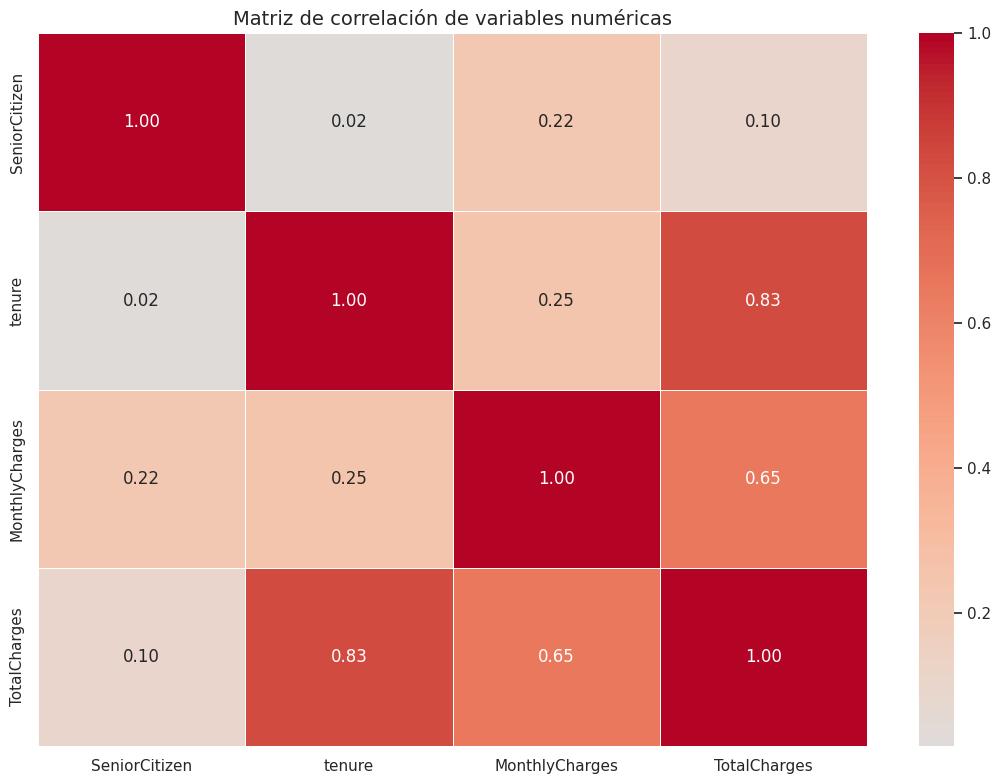

In [ ]:
numeric_df = df_eda.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

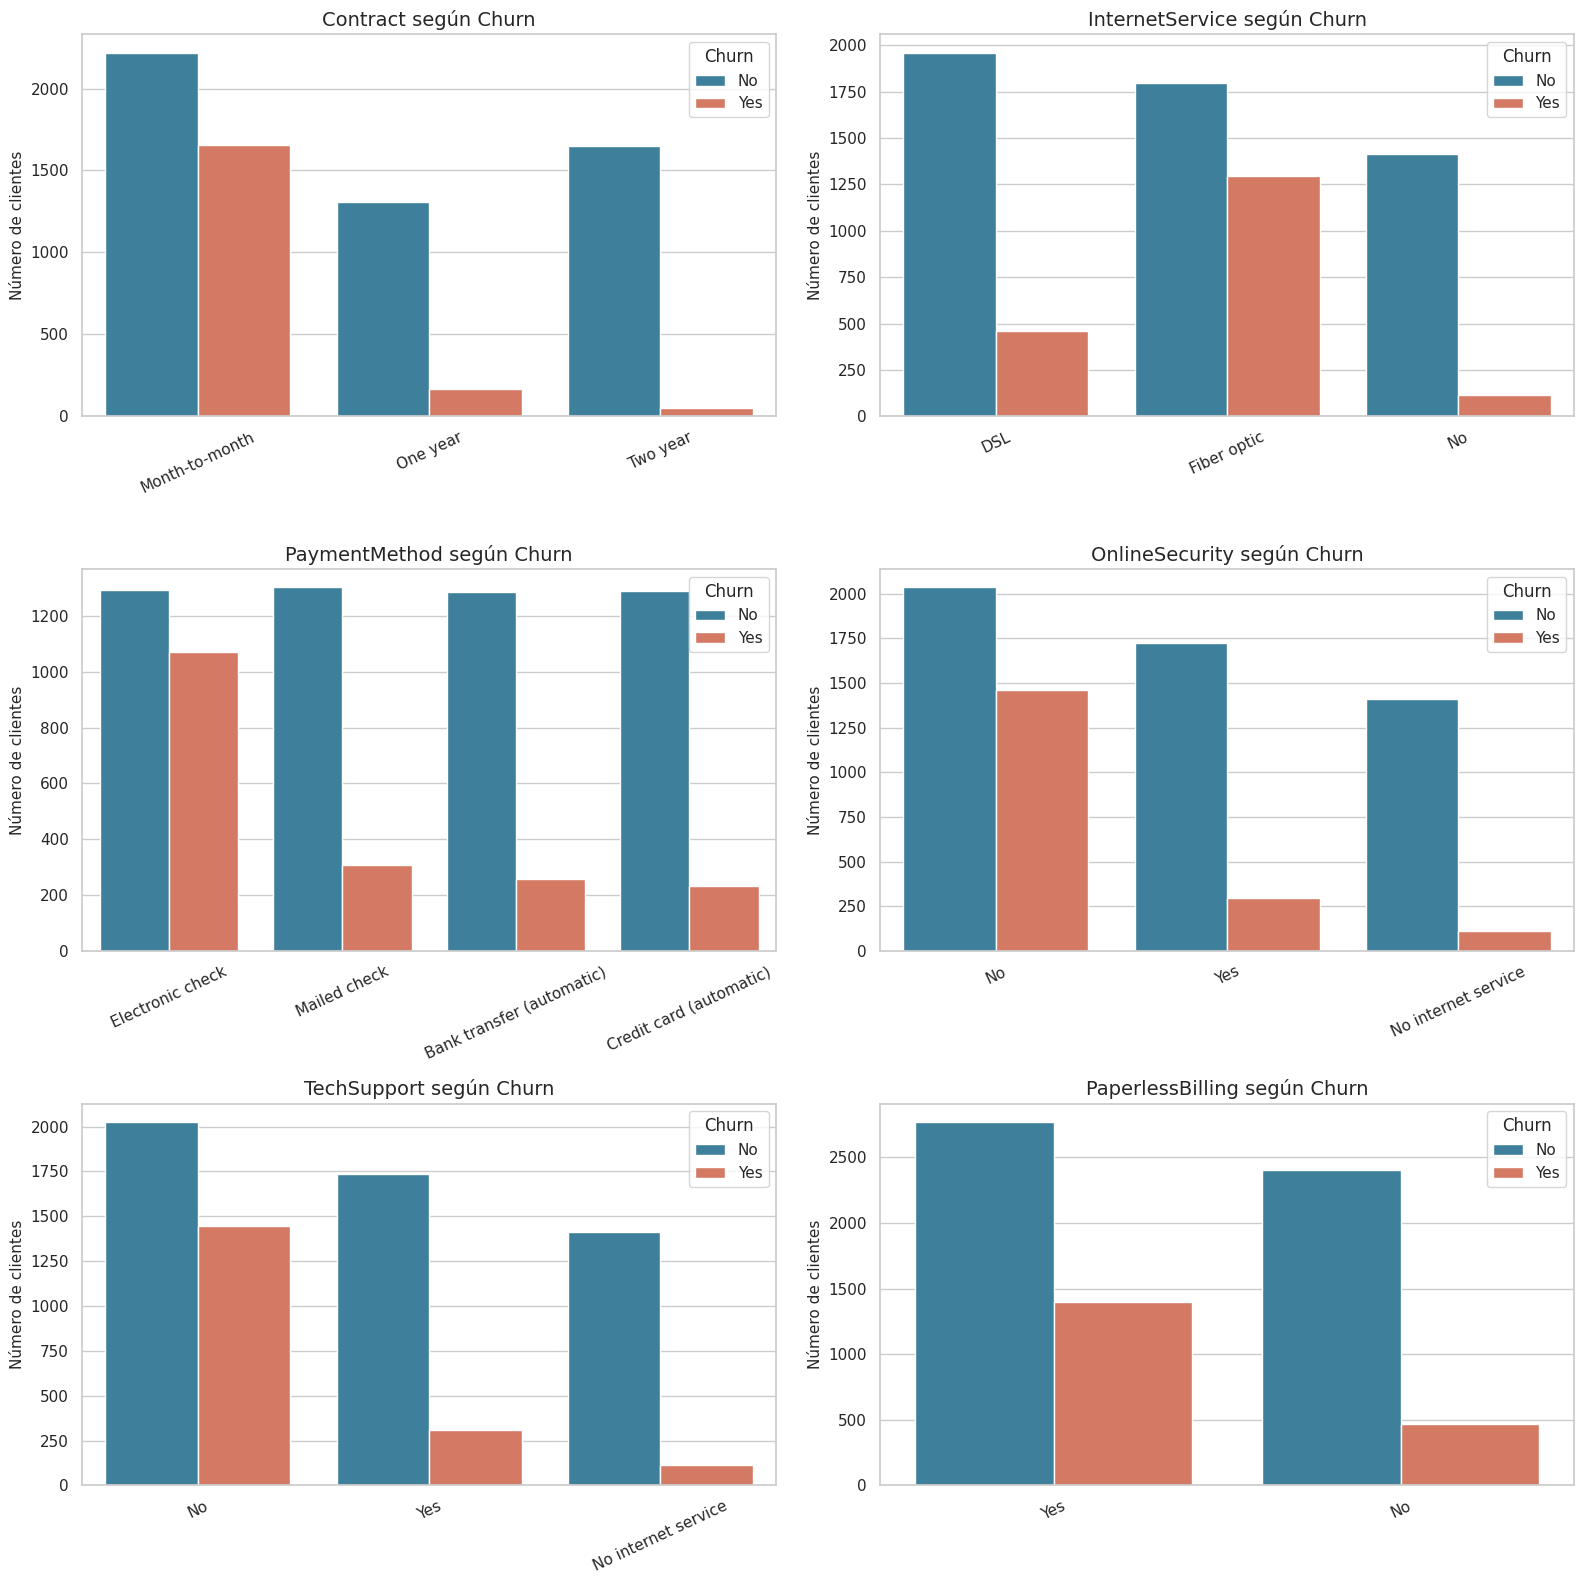

In [ ]:
categorical_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 16))

for ax, column in zip(axes.flatten(), categorical_columns):

    sns.countplot(
        data=df,
        x=column,
        hue="Churn",
        ax=ax,
        palette={"No": "#2E86AB", "Yes": "#E76F51"}
    )

    ax.set_title(f"{column} según Churn")
    ax.set_xlabel("")
    ax.set_ylabel("Número de clientes")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


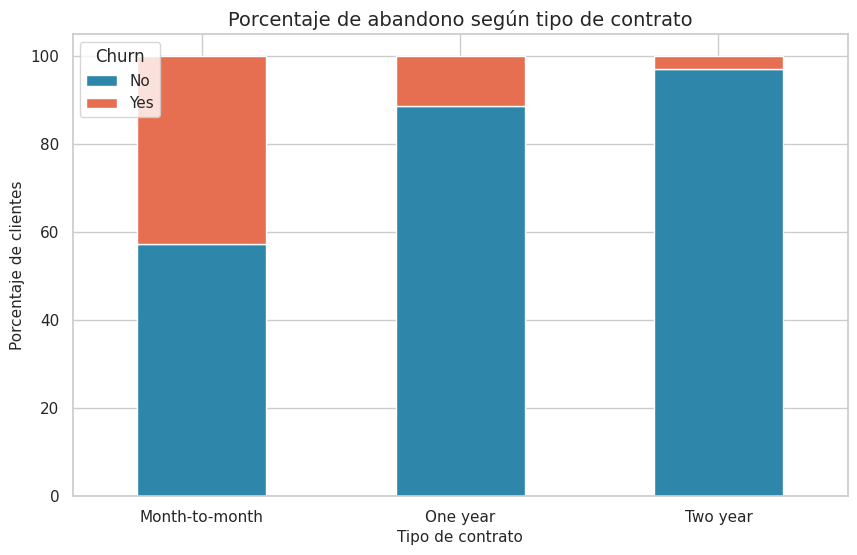

In [ ]:
churn_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(churn_contract)

churn_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#2E86AB", "#E76F51"]
)

plt.title("Porcentaje de abandono según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Porcentaje de clientes")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [ ]:
print("========== RESUMEN DEL DATASET ==========")

print(f"Total de clientes: {len(df)}")

print(f"Clientes que abandonan: {(df['Churn'] == 'Yes').sum()}")

print(f"Clientes que permanecen: {(df['Churn'] == 'No').sum()}")

print(f"Tasa de abandono: {(df['Churn'] == 'Yes').mean() * 100:.2f}%")

print(f"Registros duplicados: {df.duplicated().sum()}")

print(f"Valores vacíos en TotalCharges: "
      f"{df['TotalCharges'].str.strip().eq('').sum()}")

print("=========================================")

========== RESUMEN DEL DATASET ==========
Total de clientes: 7043
Clientes que abandonan: 1869
Clientes que permanecen: 5174
Tasa de abandono: 26.54%
Registros duplicados: 0
Valores vacíos en TotalCharges: 11


In [11]:
# Crear una copia del dataset original
df_clean = df.copy()

print("Copia de trabajo creada correctamente")
print("Dimensiones:", df_clean.shape)

Copia de trabajo creada correctamente
Dimensiones: (7043, 21)


In [12]:
# Comprobar duplicados completos
print("Registros duplicados:", df_clean.duplicated().sum())

# Comprobar identificadores duplicados
print("CustomerID duplicados:",
      df_clean["customerID"].duplicated().sum())

Registros duplicados: 0
CustomerID duplicados: 0


In [13]:
# Eliminar espacios al principio y al final de los textos
for column in df_clean.select_dtypes(include="object").columns:
    df_clean[column] = df_clean[column].str.strip()

# Convertir cadenas vacías en valores NaN
df_clean.replace("", np.nan, inplace=True)

print("Normalización de textos completada")

Normalización de textos completada


In [14]:


# Calcular valores ausentes
missing_values = pd.DataFrame({
    "Nulos": df_clean.isnull().sum(),
    "Porcentaje": df_clean.isnull().mean() * 100
})

display(
    missing_values[missing_values["Nulos"] > 0]
)

,Nulos,Porcentaje
TotalCharges,11,0.16


In [15]:
# Mostrar registros con TotalCharges ausente
missing_total = df_clean[df_clean["TotalCharges"].isnull()]

display(
    missing_total[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [16]:
# Convertir TotalCharges a formato numérico
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Comprobar tipo de dato
print("Tipo de dato:", df_clean["TotalCharges"].dtype)

Tipo de dato: float64


In [17]:
# Sustituir TotalCharges por cero cuando tenure sea cero
df_clean.loc[
    (df_clean["tenure"] == 0) &
    (df_clean["TotalCharges"].isnull()),
    "TotalCharges"
] = 0

print(
    "Valores ausentes restantes:",
    df_clean["TotalCharges"].isnull().sum()
)

Valores ausentes restantes: 0


In [18]:
# Resumen de valores ausentes
print("Valores ausentes por columna:")
display(df_clean.isnull().sum())

print("\nTotal de valores ausentes:",
      df_clean.isnull().sum().sum())

print("\nTipo de TotalCharges:",
      df_clean["TotalCharges"].dtype)

Valores ausentes por columna:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Total de valores ausentes: 0

Tipo de TotalCharges: float64


In [22]:
# Separar variables predictoras y variable objetivo

X = df_clean.drop(columns=["customerID", "Churn"])

y = df_clean["Churn"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

Dimensiones de X: (7043, 19)
Dimensiones de y: (7043,)

Variables predictoras:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Variable objetivo:
Churn


In [23]:
# Codificar variable objetivo

y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split

# División de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensiones de los conjuntos:")
print("-----------------------------")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Dimensiones de los conjuntos:
-----------------------------
X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [28]:
# Identificar variables numéricas
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identificar variables categóricas
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("VARIABLES NUMÉRICAS:")
print(numeric_features)

print("\nVARIABLES CATEGÓRICAS:")
print(categorical_features)

print("\nTotal de variables:",
      len(numeric_features) + len(categorical_features))

VARIABLES NUMÉRICAS:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

VARIABLES CATEGÓRICAS:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total de variables: 19


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [32]:
# Pipeline para variables numéricas

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Unificar los transformadores

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocesador creado correctamente")

Preprocesador creado correctamente


In [33]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Entrenamiento:", X_train_model.shape)
print("Validación:", X_val.shape)
print("Test reservado:", X_test.shape)

Entrenamiento: (4507, 19)
Validación: (1127, 19)
Test reservado: (1409, 19)


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Crear pipeline completo
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Modelo Logistic Regression creado correctamente")

Modelo Logistic Regression creado correctamente


In [35]:
# Entrenar el modelo
logistic_model.fit(X_train_model, y_train_model)

print("Entrenamiento completado correctamente")

Entrenamiento completado correctamente


In [36]:
# Predicciones de clasificación
y_pred = logistic_model.predict(X_val)

# Probabilidades de abandono
y_proba = logistic_model.predict_proba(X_val)[:, 1]

# Mostrar algunas predicciones
results = pd.DataFrame({
    "Real": y_val.values[:10],
    "Predicción": y_pred[:10],
    "Probabilidad_abandono": y_proba[:10]
})

display(results)

,Real,Predicción,Probabilidad_abandono
0,0,0,0.20
1,0,0,0.02
2,0,0,0.05
3,0,0,0.17
4,0,0,0.25
5,0,0,0.04
6,0,0,0.18
7,0,0,0.01
8,0,0,0.02
9,0,0,0.24


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calcular métricas
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
roc_auc = roc_auc_score(y_val, y_proba)

# Mostrar resultados
print("===== LOGISTIC REGRESSION =====")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nInforme de clasificación:")
print(classification_report(
    y_val,
    y_pred,
    target_names=["No abandona", "Abandona"]
))

===== LOGISTIC REGRESSION =====
Accuracy:  0.8154
Precision: 0.6936
Recall:    0.5452
F1-score:  0.6105
ROC-AUC:   0.8482

Informe de clasificación:
              precision    recall  f1-score   support

 No abandona       0.85      0.91      0.88       828
    Abandona       0.69      0.55      0.61       299

    accuracy                           0.82      1127
   macro avg       0.77      0.73      0.74      1127
weighted avg       0.81      0.82      0.81      1127



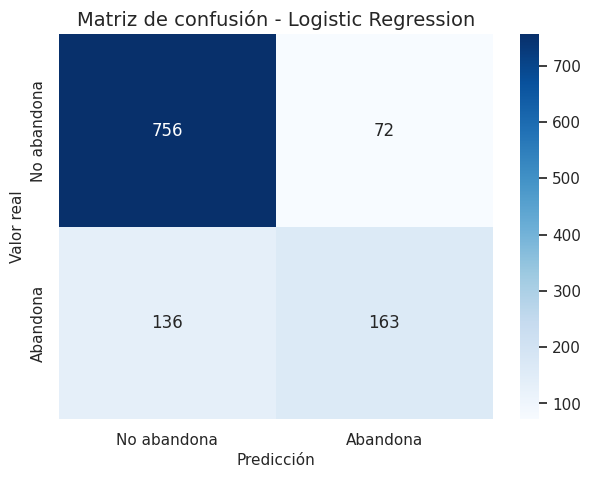

In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No abandona", "Abandona"],
    yticklabels=["No abandona", "Abandona"]
)

plt.title("Matriz de confusión - Logistic Regression")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

In [39]:
# Predicciones sobre entrenamiento y validación
y_train_pred = logistic_model.predict(X_train_model)
y_val_pred = logistic_model.predict(X_val)

# Calcular accuracy
train_accuracy = accuracy_score(y_train_model, y_train_pred)
val_accuracy = accuracy_score(y_val, y_val_pred)

# Diferencia en puntos porcentuales
overfitting_gap = abs(train_accuracy - val_accuracy) * 100

print(f"Accuracy entrenamiento: {train_accuracy:.4f}")
print(f"Accuracy validación: {val_accuracy:.4f}")
print(f"Diferencia: {overfitting_gap:.2f}%")

Accuracy entrenamiento: 0.8023
Accuracy validación: 0.8154
Diferencia: 1.31%


In [ ]:
#Inicio de entrenamiento boosting

In [40]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

In [41]:
# Crear modelo Gradient Boosting

gradient_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

print("Gradient Boosting creado correctamente")

Gradient Boosting creado correctamente


In [42]:
# Entrenar Gradient Boosting

gradient_model.fit(X_train_model, y_train_model)

print("Entrenamiento de Gradient Boosting completado")

Entrenamiento de Gradient Boosting completado


In [43]:
# Predicciones sobre validación

y_pred_gb = gradient_model.predict(X_val)

# Probabilidades de abandono
y_proba_gb = gradient_model.predict_proba(X_val)[:, 1]

# Mostrar primeras predicciones
results_gb = pd.DataFrame({
    "Real": y_val.values[:10],
    "Predicción": y_pred_gb[:10],
    "Probabilidad_abandono": y_proba_gb[:10]
})

display(results_gb)

,Real,Predicción,Probabilidad_abandono
0,0,0,0.22
1,0,0,0.02
2,0,0,0.04
3,0,0,0.12
4,0,0,0.21
5,0,0,0.07
6,0,0,0.20
7,0,0,0.03
8,0,0,0.03
9,0,0,0.18


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calcular métricas
accuracy_gb = accuracy_score(y_val, y_pred_gb)
precision_gb = precision_score(y_val, y_pred_gb)
recall_gb = recall_score(y_val, y_pred_gb)
f1_gb = f1_score(y_val, y_pred_gb)
roc_auc_gb = roc_auc_score(y_val, y_proba_gb)

# Mostrar resultados
print("===== GRADIENT BOOSTING =====")

print(f"Accuracy:  {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall:    {recall_gb:.4f}")
print(f"F1-score:  {f1_gb:.4f}")
print(f"ROC-AUC:   {roc_auc_gb:.4f}")

print("\nInforme de clasificación:")

print(classification_report(
    y_val,
    y_pred_gb,
    target_names=["No abandona", "Abandona"]
))

===== GRADIENT BOOSTING =====
Accuracy:  0.8048
Precision: 0.6872
Recall:    0.4849
F1-score:  0.5686
ROC-AUC:   0.8508

Informe de clasificación:
              precision    recall  f1-score   support

 No abandona       0.83      0.92      0.87       828
    Abandona       0.69      0.48      0.57       299

    accuracy                           0.80      1127
   macro avg       0.76      0.70      0.72      1127
weighted avg       0.79      0.80      0.79      1127



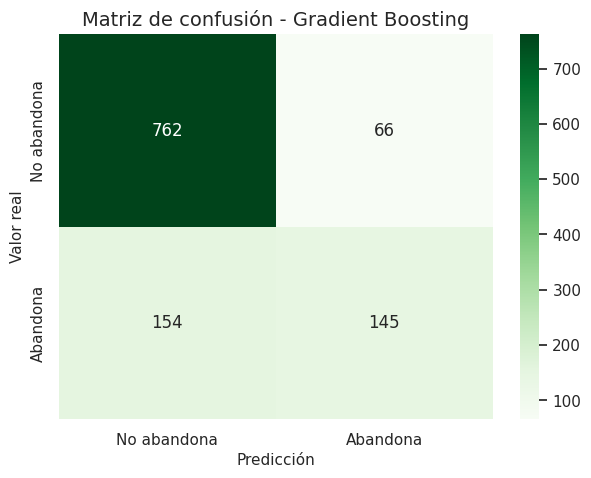

In [45]:
cm_gb = confusion_matrix(y_val, y_pred_gb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No abandona", "Abandona"],
    yticklabels=["No abandona", "Abandona"]
)

plt.title("Matriz de confusión - Gradient Boosting")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

In [47]:
# Predicciones en entrenamiento
y_train_pred_gb = gradient_model.predict(X_train_model)

# Accuracy
train_accuracy_gb = accuracy_score(
    y_train_model,
    y_train_pred_gb
)

val_accuracy_gb = accuracy_score(
    y_val,
    y_pred_gb
)

# Diferencia
overfitting_gap_gb = abs(
    train_accuracy_gb - val_accuracy_gb
) * 100

print("===== OVERFITTING GRADIENT BOOSTING =====")
print(f"Accuracy entrenamiento: {train_accuracy_gb:.4f}")
print(f"Accuracy validación: {val_accuracy_gb:.4f}")
print(f"Diferencia: {overfitting_gap_gb:.2f}%")


===== OVERFITTING GRADIENT BOOSTING =====
Accuracy entrenamiento: 0.8294
Accuracy validación: 0.8048
Diferencia: 2.46%


In [48]:
#comparacion de los dos algoritmos

comparison = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy,
        accuracy_gb
    ],
    "Precision": [
        precision,
        precision_gb
    ],
    "Recall": [
        recall,
        recall_gb
    ],
    "F1-score": [
        f1,
        f1_gb
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_gb
    ]
})

display(
    comparison.set_index("Modelo").round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,
Logistic Regression,0.82,0.69,0.55,0.61,0.85
Gradient Boosting,0.80,0.69,0.48,0.57,0.85
